# 04 · Sesgo del experto

**Pregunta.** ¿Cuánto del error de transferencia viene de las etiquetas del catálogo y no del clasificador? Dos piezas:

1. **Confident learning en Hudson** (OVDAS): con probabilidades fuera de muestra (XGBoost y regresión logística), cleanlab marca los eventos cuya etiqueta del analista es poco probable. Se resume por clase y se contrasta con la revisión manual de una muestra.
2. **Criterio HB/LP en el onset**: fracción de energía de alta frecuencia al inicio del evento (`HF_onset`) por cuartil de SNR, HB frente a LP, en Hudson, Copahue, Ruiz-Olleta y Ruiz-Bis. Si HB y LP se distinguen por el onset en un sistema y no en otro, el criterio del experto cambia entre observatorios.

Todo se muestra por sistema. Lee solo `../resultados/` (valores agregados; la tabla de revisión manual tiene ~200 eventos de Hudson).

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

## 1. Confident learning en Hudson: sospechosos por clase

In [2]:
cl = pd.read_csv(RES / "sesgo_experto_hudson_cleanlab_por_clase.csv")
cl[["modelo", "clase", "n", "n_sospechosos", "frac_sospechosos", "snr_mediana_sospechosos",
    "snr_mediana_resto", "sugiere_AV", "sugiere_HB", "sugiere_LP", "sugiere_VT"]].round(3)

,modelo,clase,n,n_sospechosos,frac_sospechosos,snr_mediana_sospechosos,snr_mediana_resto,sugiere_AV,sugiere_HB,sugiere_LP,sugiere_VT
0,xgb,AV,7682,1684,0.219,11.393,13.791,0,6,840,838
1,xgb,HB,483,281,0.582,20.036,20.596,82,0,54,145
2,xgb,LP,10940,1125,0.103,9.813,11.089,875,17,0,233
3,xgb,VT,15035,1022,0.068,10.350,6.992,763,17,242,0
4,logreg,AV,7682,2498,0.325,12.028,13.768,0,0,952,1546
5,logreg,HB,483,327,0.677,20.426,20.120,102,0,97,128
6,logreg,LP,10940,1228,0.112,9.793,11.115,836,0,0,392
7,logreg,VT,15035,1417,0.094,10.027,6.992,1085,2,330,0


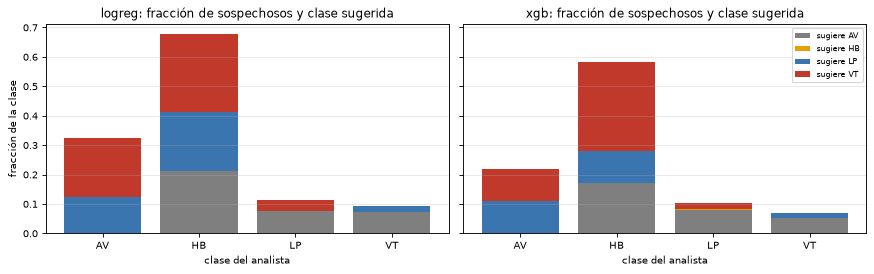

In [3]:
COLOR = {"AV": "#7f7f7f", "HB": "#e69f00", "LP": "#3b75af", "VT": "#c0392b"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (mod, g) in zip(ejes, cl.groupby("modelo")):
    g = g.set_index("clase")
    base = np.zeros(len(g))
    for c in ["AV", "HB", "LP", "VT"]:
        v = g[f"sugiere_{c}"] / g.n
        ax.bar(g.index, v, bottom=base, color=COLOR[c], label=f"sugiere {c}")
        base += v.values
    ax.set_title(f"{mod}: fracción de sospechosos y clase sugerida")
    ax.set_xlabel("clase del analista"); ax.grid(axis="y", alpha=.3)
ejes[0].set_ylabel("fracción de la clase"); ejes[1].legend(fontsize=7)
fig.tight_layout()

### Agrupamiento no supervisado (HDBSCAN/DBSCAN) frente a las etiquetas

In [4]:
pd.read_csv(RES / "sesgo_experto_hudson_agrupamiento.csv")[
    ["representacion", "metodo", "n_grupos", "frac_ruido", "dbcv", "ARI_todos", "NMI_todos"]].round(3)

,representacion,metodo,n_grupos,frac_ruido,dbcv,ARI_todos,NMI_todos
0,PCA16,HDBSCAN,2,0.175,0.327,0.023,0.050
1,PCA16,DBSCAN,112,0.825,0.035,-0.035,0.100
2,FI_DET_SR,HDBSCAN,3,0.837,0.086,0.027,0.110
3,FI_DET_SR,DBSCAN,227,0.686,0.100,0.012,0.129


### Revisión manual de la muestra de sospechosos

`sesgo_experto_hudson_revision_manual.csv`: eventos de la cola de revisión con la clase original y la sugerida. `onset_hb_lp_hudson_revision.csv`: clase final asignada en la revisión manual, con SNR, ΔFI y `HF_onset` medianos.

In [5]:
rv = pd.read_csv(RES / "sesgo_experto_hudson_revision_manual.csv")
pd.crosstab(rv.clase, rv.sugerida_xgb, margins=True, margins_name="total")

sugerida_xgb,AV,HB,LP,VT,total
clase,,,,,
AV,0,0,17,8,25
HB,23,0,29,50,102
LP,7,0,0,36,43
VT,1,1,28,0,30
total,31,1,74,94,200


,final,n,snr,dFI,HF_onset
0,AV,18,16.765,0.132,0.570
1,HB,31,25.380,0.435,0.498
2,LP,24,19.597,0.475,0.201
3,VT,29,19.337,0.484,0.631


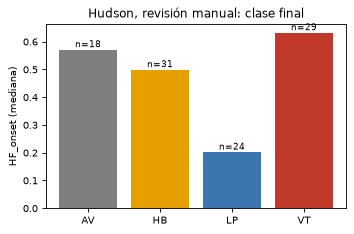

In [6]:
rev = pd.read_csv(RES / "onset_hb_lp_hudson_revision.csv")
display(rev)
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(rev.final, rev.HF_onset, color=[COLOR.get(c, "k") for c in rev.final])
for i, (n, v) in enumerate(zip(rev.n, rev.HF_onset)):
    ax.text(i, v + .01, f"n={n}", ha="center", fontsize=8)
ax.set_ylabel("HF_onset (mediana)"); ax.set_title("Hudson, revisión manual: clase final")
fig.tight_layout()

## 2. Criterio HB/LP: alta frecuencia en el onset por cuartil de SNR

Si el analista separa HB de LP por el inicio impulsivo, `HF_onset` debe ser mayor en HB que en LP **dentro de cada cuartil de SNR** (así se descarta que la diferencia sea solo de SNR).

In [7]:
partes = [pd.read_csv(RES / "onset_hb_lp_hudson_resumen.csv").assign(sistema="Hudson"),
          pd.read_csv(RES / "onset_hb_lp_copahue_resumen.csv"),
          pd.read_csv(RES / "onset_hb_lp_ruiz_resumen.csv")]
o = pd.concat(partes, ignore_index=True)
o.pivot_table(index=["sistema", "q"], columns="label", values=["HF_onset", "n", "snr"]).round(3)

HF_onset             n            snr        
label               HB     LP     HB     LP      HB      LP
sistema     q                                              
Copahue     0    0.591  0.284  535.0  465.0   0.605   0.819
            1    0.576  0.218  504.0  496.0   3.555   3.499
            2    0.550  0.205  552.0  448.0   5.982   5.921
            3    0.605  0.216  409.0  591.0   9.048  10.703
Hudson      0    0.379  0.142   36.0  585.0   6.032   6.401
            1    0.471  0.133   45.0  575.0  10.511  10.149
            2    0.437  0.116   94.0  526.0  14.964  14.114
            3    0.439  0.098  308.0  312.0  26.070  19.741
Ruiz-Bis    0    0.626  0.814    8.0   43.0   4.196   3.760
            1    0.739  0.726    9.0   41.0   7.064   6.388
            2    0.783  0.768   18.0   32.0   9.520   9.287
            3    0.662  0.732   28.0   23.0  13.888  13.667
Ruiz-Olleta 0    0.682  0.691   88.0   38.0   5.652   4.548
            1    0.700  0.749   94.0   31.0   9.853  10.344
            2    0.663  0.698   94.0   31.0  15.844  15.801
            3    0.618  0.576   83.0   42.0  25.316  28.910

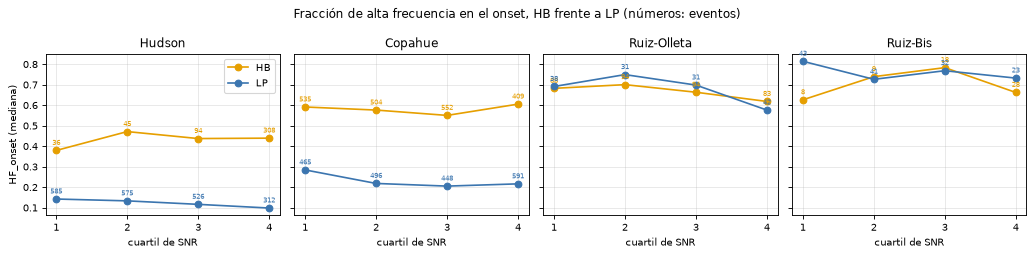

In [8]:
sist = ["Hudson", "Copahue", "Ruiz-Olleta", "Ruiz-Bis"]
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, s in zip(ejes, sist):
    g = o[o.sistema == s]
    for lab, h in g.groupby("label"):
        h = h.sort_values("q")
        ax.plot(h.q + 1, h.HF_onset, "-o", color=COLOR[lab], label=lab)
        for x, y, n in zip(h.q + 1, h.HF_onset, h.n):
            ax.annotate(str(n), (x, y), textcoords="offset points", xytext=(0, 5), fontsize=6,
                        ha="center", color=COLOR[lab])
    ax.set_title(s); ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("cuartil de SNR"); ax.grid(alpha=.3)
ejes[0].set_ylabel("HF_onset (mediana)"); ejes[0].legend()
fig.suptitle("Fracción de alta frecuencia en el onset, HB frente a LP (números: eventos)")
fig.tight_layout()

In [9]:
dif = (o.pivot_table(index=["sistema", "q"], columns="label", values="HF_onset")
       .eval("HB - LP").rename("HF_onset HB − LP").unstack("q"))
dif.round(3)

q,0,1,2,3
sistema,,,,
Copahue,0.307,0.358,0.345,0.389
Hudson,0.237,0.338,0.321,0.341
Ruiz-Bis,-0.188,0.013,0.015,-0.070
Ruiz-Olleta,-0.009,-0.049,-0.035,0.042
